In [1]:
import cantera as ct
import numpy as np 
import pandas as pd

import matplotlib.pyplot as plt

%matplotlib inline

# Task 1 -  Equivalence Ratio Sweep

In [2]:
def equilibrium_temperature(phi, fuel="H2", T_u=300.0, p=101325.0,
                             mechanism="h2o2.yaml",
                             oxidizer="O2:1, N2:3.76"):
    """
    Return the adiabatic flame temperature for a single condition.

    Parameters
    ----------
    phi : float
        Equivalence ratio.
    fuel : str
        Cantera fuel string (default: "H2").
    T_u : float
        Unburned mixture temperature in K (default: 300 K).
    p : float
        Pressure in Pa (default: 1 atm).
    mechanism : str
        Cantera mechanism file (default: "h2o2.yaml").
    oxidizer : str
        Oxidizer composition string (default: "O2:1, N2:3.76").

    Returns
    -------
    float
        Adiabatic flame temperature in K.
    """
    ...

    gas = ct.Solution(mechanism)
    gas.set_equivalence_ratio(phi, fuel, oxidizer)
    gas.TP = T_u, p

    gas.equilibrate("HP")

    return gas.T


In [4]:
phi = 1.0
T_H2 = equilibrium_temperature(phi)

print(f"Adiabatic flame temperature for {phi} equivalence ratio: {T_H2:.2f} K")

Adiabatic flame temperature for 1.0 equivalence ratio: 2387.64 K


In [5]:
def equilibrium_sweep(phi_range, fuel="H2", T_u=300.0, p=101325.0,
                      mechanism="h2o2.yaml", oxidizer="O2:1, N2:3.76"):
    """
    Return T_ad for an array of equivalence ratios.

    Parameters
    ----------
    phi_range : array-like
        Array of equivalence ratios.

    Returns
    -------
    numpy.ndarray
        Adiabatic flame temperatures in K, same shape as phi_range.
    """
    ...

    phi_range = np.asarray(phi_range, dtype=float)
    states = ct.SolutionArray(ct.Solution(mechanism), shape=phi_range.shape)
    states.set_equivalence_ratio(phi_range, fuel, oxidizer)
    states.TP = T_u, p
    states.equilibrate("HP")
    return states.T

Peak adiabatic flame temperature occurs at phi = 1.09


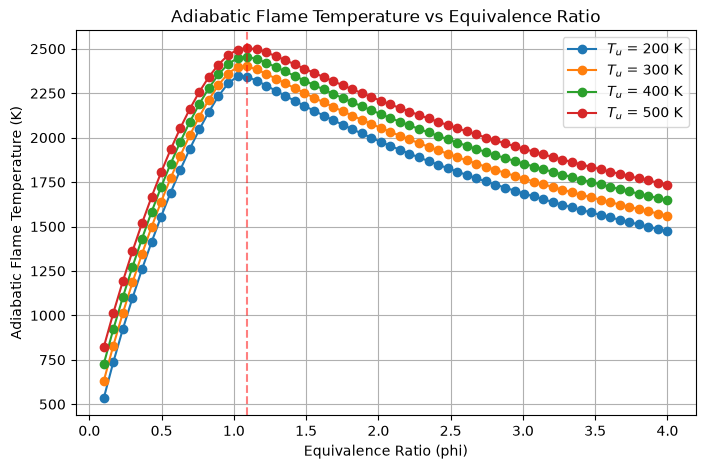

In [28]:
phi_min = 0.1
phi_max = 4.0

plt.figure(figsize=(8, 5))
for T_u in [200, 300, 400, 500]:
    phi_values = np.linspace(phi_min, phi_max, 60)
    T_ad_values = equilibrium_sweep(phi_values, T_u=T_u)

    plt.plot(phi_values, T_ad_values, marker='o', label=f"$T_u$ = {T_u} K")

peak = np.argmax(T_ad_values)
plt.axvline(x=phi_values[peak], color='red', linestyle='--', alpha=0.5)


print(f"Peak adiabatic flame temperature occurs at phi = {phi_values[peak]:.2f}")

plt.title("Adiabatic Flame Temperature vs Equivalence Ratio")
plt.xlabel("Equivalence Ratio (phi)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()
plt.legend()
plt.show()

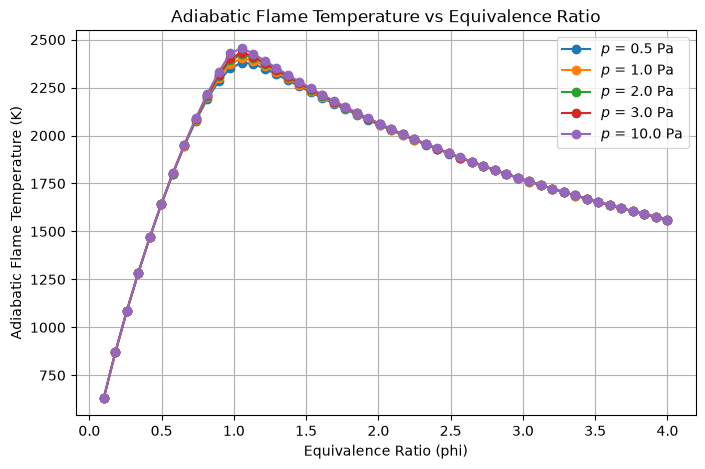

In [17]:
p_atm = ct.one_atm

phi_min = 0.1
phi_max = 4.0

plt.figure(figsize=(8, 5))
for p in [0.5, 1.0, 2.0, 3.0,10.0]:
    phi_values = np.linspace(phi_min, phi_max, 50)
    T_ad_values = equilibrium_sweep(phi_values, p=p * p_atm)

    plt.plot(phi_values, T_ad_values, marker='o', label=f"$p$ = {p} Pa")

plt.title("Adiabatic Flame Temperature vs Equivalence Ratio")
plt.xlabel("Equivalence Ratio (phi)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()
plt.legend()
plt.show()

# Task 2 - Preheat Temperature Sweep

In [ ]:
def equilibrium_sweep_Tu(T_u_range, phi=1.0, fuel="H2", p=101325.0,
                         mechanism="h2o2.yaml", oxidizer="O2:1, N2:3.76"):
    """Return T_ad for an array of unburned temperatures."""

    T_u_range = np.asarray(T_u_range, dtype=float)
    states = ct.SolutionArray(ct.Solution(mechanism), shape=T_u_range.shape)
    states.set_equivalence_ratio(phi, fuel, oxidizer)
    states.TP = T_u_range, p
    states.equilibrate("HP")
    return states.T

In [30]:
equilibrium_sweep_Tu([200, 300, 400, 500])

array([2334.67298638, 2387.63690001, 2438.11277218, 2485.95587179])

In [54]:
gradient

array([0.85427384, 0.85439156, 0.85445167, 0.85449856, 0.85456934,
       0.85469393, 0.85489511, 0.85518858, 0.85558297, 0.85607992,
       0.85667407, 0.85735313, 0.85809794, 0.85888253, 0.85967421,
       0.86043375, 0.8611155 , 0.86166769, 0.86203268])

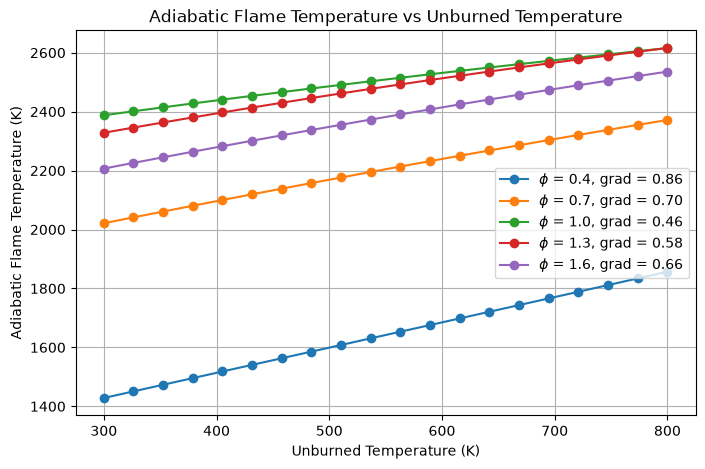

In [58]:
plt.figure(figsize=(8, 5))

for phi in [0.4, 0.7, 1.0, 1.3, 1.6]:
    Ts = np.linspace(300, 800, 20)
    Tad_values = equilibrium_sweep_Tu(Ts, phi=phi)

    gradient = (Tad_values[-1] - Tad_values[0])/(Ts[-1] - Ts[0])
    plt.plot(Ts, Tad_values, marker='o', label=f"$\\phi$ = {phi}, grad = {gradient:.2f}")

plt.legend()
plt.title("Adiabatic Flame Temperature vs Unburned Temperature")
plt.xlabel("Unburned Temperature (K)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()

array([0.73079591, 0.72795811, 0.7218909 , 0.71509991, 0.707699  ,
       0.69979191, 0.69147223, 0.68282334, 0.67391856, 0.66482134,
       0.65558544, 0.64625538, 0.63686683, 0.6274471 , 0.61801577,
       0.60858526, 0.59916153, 0.58974471, 0.58032982, 0.57562193])

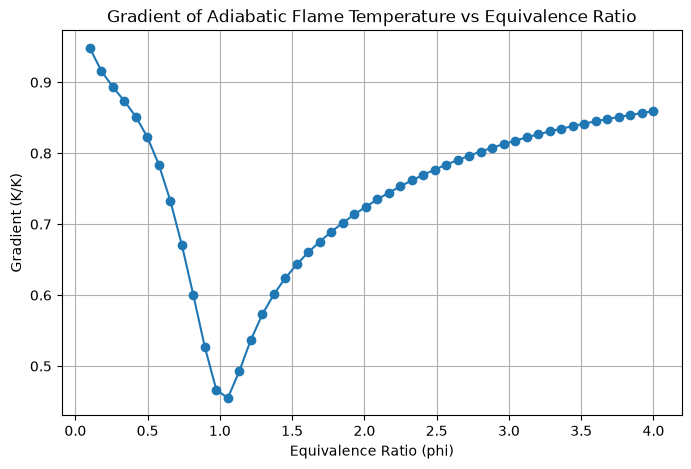

In [59]:
phis = np.linspace(0.1, 4.0, 50)
grads = np.zeros_like(phis)
for i, phi in enumerate(phis):
    Ts = np.linspace(300, 800, 20)
    Tad_values = equilibrium_sweep_Tu(Ts, phi=phi)

    gradient = (Tad_values[-1] - Tad_values[0])/(Ts[-1] - Ts[0])
    grads[i] = gradient

plt.figure(figsize=(8, 5))
plt.plot(phis, grads, marker='o')
plt.title("Gradient of Adiabatic Flame Temperature vs Equivalence Ratio")
plt.xlabel("Equivalence Ratio (phi)")
plt.ylabel("Gradient (K/K)")
plt.grid()


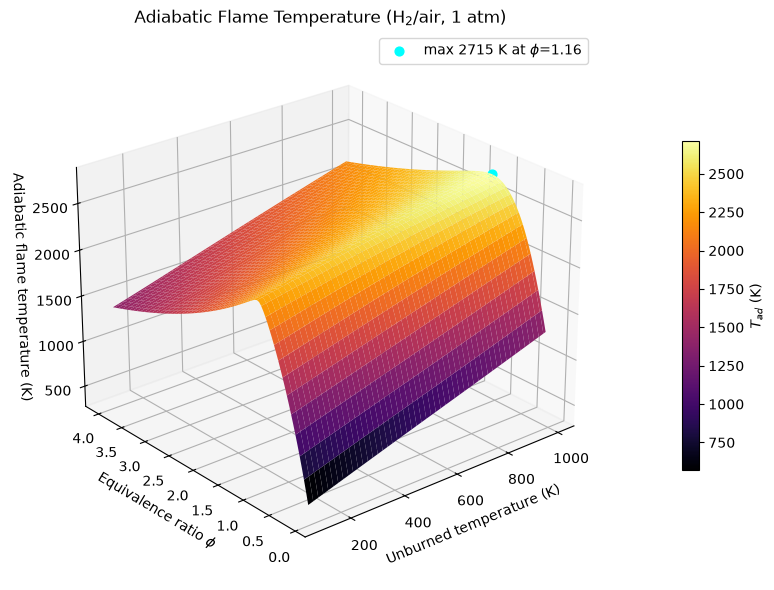

In [61]:
Ts   = np.linspace(100, 1000, 100)       # unburned temperature (K)
phis = np.linspace(0.1, 4.0, 100)       # equivalence ratio

TU, PHI = np.meshgrid(Ts, phis)        # both shape (len(phis), len(Ts))
TAD = np.array([equilibrium_sweep_Tu(Ts, phi=phi) for phi in phis])

fig = plt.figure(figsize=(9, 6))
ax  = fig.add_subplot(projection="3d")
surf = ax.plot_surface(TU, PHI, TAD, cmap="inferno", edgecolor="none")

# Mark the hottest point on the grid
i, j = np.unravel_index(np.argmax(TAD), TAD.shape)
ax.scatter(TU[i, j], PHI[i, j], TAD[i, j], color="cyan", s=40,
           label=f"max {TAD[i, j]:.0f} K at $\\phi$={PHI[i, j]:.2f}")

ax.set_xlabel("Unburned temperature (K)")
ax.set_ylabel("Equivalence ratio $\\phi$")
ax.set_zlabel("Adiabatic flame temperature (K)")
ax.set_title("Adiabatic Flame Temperature (H$_2$/air, 1 atm)")
fig.colorbar(surf, shrink=0.6, pad=0.1, label="$T_{ad}$ (K)")
ax.view_init(elev=25, azim=-130)       # change these to rotate the view
ax.legend()
plt.tight_layout()